# The Mandelbrot Set

In this notebook I compute and plot the Mandelbrot set with Python (`numpy` and `matplotlib`).
To change the region that is drawn, the resolution or the number of iterations, edit the **Parameters** cell (section 4) and run it again.

## 1. Definition

For each complex number $c \in \mathbb{C}$ we look at the sequence

$$z_0 = 0, \qquad z_{n+1} = z_n^2 + c .$$

The Mandelbrot set is the set of all $c$ for which this sequence **stays bounded**:

$$\mathcal{M} = \{\, c \in \mathbb{C} : (z_n)_{n \ge 0} \text{ is bounded} \,\}.$$

For example, $c = 0$ belongs to $\mathcal{M}$ (the sequence is always $0$), so does $c = -1$ (it alternates between $0$ and $-1$), and $c = 1$ does not (it gives $0, 1, 2, 5, 26, \dots$).

## 2. Escape criterion

We cannot iterate forever, so we need a criterion to tell when a sequence is going to infinity.

**Claim.** If $|c| \le 2$ and $|z_n| > 2$ for some $n$, then $|z_k| \to \infty$.

*Idea of the proof.* If $|z| > 2 \ge |c|$:

$$|z^2 + c| \ge |z|^2 - |c| > |z|^2 - |z| = |z|\,(|z| - 1).$$

Since $|z| - 1 > 1$, the modulus of the next term is larger than $|z|$ times a factor greater than $1$ (and that factor keeps growing), so the modulus tends to infinity.

Also, if $|c| > 2$ then $|z_1| = |c| > 2$ and the orbit already escapes at the first step. Hence $\mathcal{M} \subset \{ |c| \le 2 \}$, which is why the plotting window is $[-2, 0.5] \times [-1.25, 1.25]$.

In the code I fix a maximum number of iterations (`max_iter`). If a point has not escaped after `max_iter` steps, I assume it belongs to $\mathcal{M}$. This is an **approximation**: points very close to the boundary can be misclassified.

## 3. Smooth colouring

If each point is coloured only by the integer number of iterations it takes to escape, the picture shows sharp colour bands. To avoid this I use the normalised *escape time*:

$$\nu = N + 1 - \log_2\!\big(\ln |z_N|\big),$$

where $N$ is the first iteration at which $|z_N|$ exceeds the escape radius.

*Where it comes from:* when $|z_n|$ is large, $z_{n+1} \approx z_n^2$, so $\ln|z_{n+1}| \approx 2\ln|z_n|$, that is, $\ln|z_n|$ **doubles** at every step. Subtracting $\log_2(\ln|z_N|)$ turns that growth into a fractional number of steps.

To make the approximation accurate I use a large escape radius (256). Since any radius $\ge 2$ already guarantees escape, the classification stays correct.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

## 4. Parameters

These are the values you can change. Some interesting regions to try are listed in section 6.

In [2]:
# --- region of the complex plane to draw (c = x + iy) ---
x_min, x_max = -2.0, 0.5
y_min, y_max = -1.25, 1.25

# --- quality ---
resolution = 1000      # pixels per side (higher = more detail, but slower)
max_iter = 500         # maximum iterations (increase it when zooming in)

# --- appearance ---
cmap = "twilight_shifted"   # others: "magma", "viridis", "inferno", "turbo"
gamma = 0.35                # < 1 emphasises the details near the boundary

# --- save the figure ---
save = True
filename = "images/mandelbrot.png"

## 5. Computation

I work on the whole plane at once using `numpy` arrays. At each iteration I only update the points that have not escaped yet (`active`), and the points that escape store their value of $\nu$. Points that never escape stay as `NaN` and are drawn in black.

In [3]:
def mandelbrot(x_min, x_max, y_min, y_max, resolution, max_iter, radius=256):
    # grid of values of c
    x = np.linspace(x_min, x_max, resolution)
    y = np.linspace(y_min, y_max, resolution)
    X, Y = np.meshgrid(x, y)
    C = X + 1j * Y

    Z = np.zeros_like(C)                    # z_0 = 0
    nu = np.full(C.shape, np.nan)           # NaN = has not escaped (is in M)
    active = np.ones(C.shape, dtype=bool)   # points that have not escaped yet

    for n in range(1, max_iter + 1):
        Z[active] = Z[active] ** 2 + C[active]
        escaped = active & (np.abs(Z) > radius)
        nu[escaped] = n + 1 - np.log2(np.log(np.abs(Z[escaped])))
        active &= ~escaped
        if not active.any():
            break
    return nu


nu = mandelbrot(x_min, x_max, y_min, y_max, resolution, max_iter)
print("Points that never escape (approx. inside M): "
      f"{np.isnan(nu).mean():.1%}")

Points that never escape (approx. inside M): 24.2%


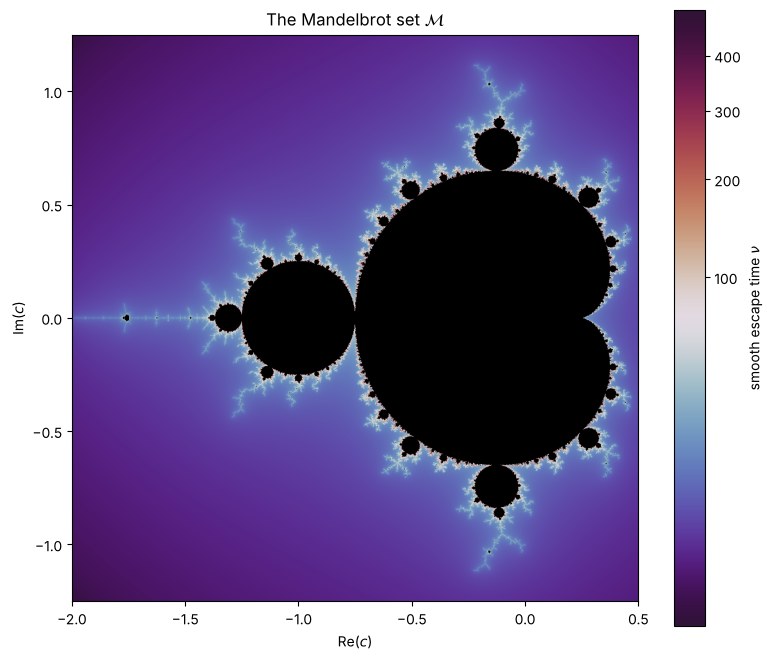

In [4]:
palette = plt.get_cmap(cmap).copy()
palette.set_bad("black")                    # interior of M in black

fig, ax = plt.subplots(figsize=(8, 8))
img = ax.imshow(np.ma.masked_invalid(nu),
                extent=[x_min, x_max, y_min, y_max],
                origin="lower", cmap=palette, norm=PowerNorm(gamma=gamma))
ax.set_title(r"The Mandelbrot set $\mathcal{M}$")
ax.set_xlabel("Re($c$)")
ax.set_ylabel("Im($c$)")
fig.colorbar(img, ax=ax, shrink=0.8, label=r"smooth escape time $\nu$")
fig.tight_layout()

if save:
    os.makedirs(os.path.dirname(filename), exist_ok=True)
    fig.savefig(filename, dpi=150)
plt.show()

## 6. Regions to explore

Copy these values into the parameters cell (and increase `max_iter`) to see different parts of the boundary:

| Region | `x_min`, `x_max` | `y_min`, `y_max` | suggested `max_iter` |
|---|---|---|---|
| Seahorse valley | $-0.75$, $-0.74$ | $0.09$, $0.10$ | 1500 |
| Elephant valley | $0.25$, $0.30$ | $0.00$, $0.05$ | 1000 |
| Mini-Mandelbrot on the real axis | $-1.78$, $-1.74$ | $-0.02$, $0.02$ | 1000 |

The boundary contains small copies of the whole set, and the deeper the zoom, the more iterations are needed to tell the points apart.

## 7. Limitations and remarks

- The result is an **approximation**: with a finite `max_iter`, some points very close to the boundary are marked as "inside" even though they eventually escape.
- With double-precision floating point numbers you cannot zoom indefinitely: from scales of roughly $10^{-13}$ the image becomes pixelated because of rounding.
- The running time grows roughly like `resolution² · max_iter` in the worst case.
- The set is symmetric with respect to the real axis (because $\overline{Q_c(z)} = Q_{\bar c}(\bar z)$), which gives a quick visual check that the code is correct.

The study continues in the notebook `julia.ipynb`, which looks at the Julia set associated with each $c$.